In [1]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [2]:
!pip -q install kagglehub

In [3]:
import kagglehub
from pathlib import Path

dataset_path = Path(
    kagglehub.dataset_download(
        "paultimothymooney/chest-xray-pneumonia"
    )
)

print("Dataset downloaded to:", dataset_path)
print("Dataset exists:", dataset_path.exists())
print("Contents:", [p.name for p in dataset_path.iterdir()])

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia
Dataset exists: True
Contents: ['chest_xray']


In [4]:
# verifying image folders

from pathlib import Path

data_root = dataset_path / "chest_xray"

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in ["NORMAL", "PNEUMONIA"]:
        folder = data_root / split / label

        if folder.exists():
            count = sum(
                1 for p in folder.iterdir()
                if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
            )
            print(f"{label}: {count}")
        else:
            print(f"{label}: folder not found")


TRAIN
NORMAL: 1341
PNEUMONIA: 3875

VAL
NORMAL: 8
PNEUMONIA: 8

TEST
NORMAL: 234
PNEUMONIA: 390


In [5]:
# creating training & validation split

from pathlib import Path
import random

random.seed(42)

data_root = dataset_path / "chest_xray"
train_root = data_root / "train"
test_root = data_root / "test"

# Check that the expected folders exist
for folder in [
    train_root / "NORMAL",
    train_root / "PNEUMONIA",
    test_root / "NORMAL",
    test_root / "PNEUMONIA",
]:
    print(folder, "->", folder.exists())

# Count the available training and test images
for split_root in [train_root, test_root]:
    print(f"\n{split_root.name.upper()}")

    for label in ["NORMAL", "PNEUMONIA"]:
        images = [
            p for p in (split_root / label).iterdir()
            if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        ]
        print(f"{label}: {len(images)}")

/kaggle/input/chest-xray-pneumonia/chest_xray/train/NORMAL -> True
/kaggle/input/chest-xray-pneumonia/chest_xray/train/PNEUMONIA -> True
/kaggle/input/chest-xray-pneumonia/chest_xray/test/NORMAL -> True
/kaggle/input/chest-xray-pneumonia/chest_xray/test/PNEUMONIA -> True

TRAIN
NORMAL: 1341
PNEUMONIA: 3875

TEST
NORMAL: 234
PNEUMONIA: 390


In [6]:
# creating reproducible file lists
# (Reserves 20% of the training images from each class for validation.)

import random
from pathlib import Path

random.seed(42)

classes = ["NORMAL", "PNEUMONIA"]
train_files = []
val_files = []
test_files = []

for label in classes:
    images = sorted([
        p for p in (train_root / label).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    random.shuffle(images)

    split_index = int(0.8 * len(images))

    train_files.extend((p, label) for p in images[:split_index])
    val_files.extend((p, label) for p in images[split_index:])

    test_images = sorted([
        p for p in (test_root / label).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ])

    test_files.extend((p, label) for p in test_images)

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Test images:", len(test_files))

print("\nTraining class counts:")
for label in classes:
    print(label, sum(y == label for _, y in train_files))

print("\nValidation class counts:")
for label in classes:
    print(label, sum(y == label for _, y in val_files))

Training images: 4172
Validation images: 1044
Test images: 624

Training class counts:
NORMAL 1072
PNEUMONIA 3100

Validation class counts:
NORMAL 269
PNEUMONIA 775


## Configuring PyTorch & Image data loaders

In [7]:
# Install and import the required libraries

import torch
import torchvision
import numpy as np

from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training will run on CPU.")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
GPU available: True
GPU: Tesla T4


In [8]:
# Create a custom dataset class

class ChestXrayDataset(Dataset):
    def __init__(self, file_list, transform=None):
        self.file_list = file_list
        self.transform = transform
        self.class_to_idx = {
            "NORMAL": 0,
            "PNEUMONIA": 1
        }

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, index):
        image_path, label = self.file_list[index]

        # Convert every image to RGB for consistency
        image = Image.open(image_path).convert("RGB")
        label = self.class_to_idx[label]

        if self.transform:
            image = self.transform(image)

        return image, label

In [9]:
# Define image transformations

IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [10]:
# Building data loaders

train_dataset = ChestXrayDataset(train_files, train_transform)
val_dataset = ChestXrayDataset(val_files, eval_transform)
test_dataset = ChestXrayDataset(test_files, eval_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 131
Validation batches: 33
Test batches: 20


In [11]:
# verifying a batch

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels in batch:", labels.tolist()[:10])
print("Image tensor dtype:", images.dtype)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels in batch: [1, 0, 1, 0, 0, 1, 1, 0, 0, 1]
Image tensor dtype: torch.float32


## Set up the pretrained ResNet18 model

In [12]:
# Load the pretrained model

import torch
from torch import nn
from torchvision.models import resnet18, ResNet18_Weights

# Choose GPU when available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)

# Load ResNet18 with pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze the pretrained feature extractor initially
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer for binary classification
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

# Move model to GPU or CPU
model = model.to(device)

print("Model: ResNet18")
print("Output classes:", model.fc.out_features)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Total parameters:",
      sum(p.numel() for p in model.parameters()))

Training device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 136MB/s]


Model: ResNet18
Output classes: 2
Trainable parameters: 1026
Total parameters: 11177538


In [13]:
# configure the loss fn & optimizer

import numpy as np
from torch import nn

class_counts = np.bincount(
    [0 if label == "NORMAL" else 1 for _, label in train_files],
    minlength=2
)

class_weights = len(train_files) / (
    2.0 * torch.tensor(class_counts, dtype=torch.float32)
)

class_weights = class_weights.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("Class counts [NORMAL, PNEUMONIA]:", class_counts)
print("Class weights:", class_weights.cpu().tolist())
print("Loss function:", criterion)
print("Optimizer: Adam")

Class counts [NORMAL, PNEUMONIA]: [1072 3100]
Class weights: [1.9458954334259033, 0.6729032397270203]
Loss function: CrossEntropyLoss()
Optimizer: Adam


In [14]:
# check that the model produces valid predictions

model.eval()

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Example class scores:", outputs[0].cpu().tolist())
print("Model device:", next(model.parameters()).device)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 2])
Example class scores: [0.843572199344635, -0.12384524941444397]
Model device: cuda:0


## Train model & validate each epoch

In [15]:
# creating training & evaluation fns

import copy
import torch
from sklearn.metrics import accuracy_score

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_preds.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy


@torch.no_grad()
def evaluate_model(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        all_preds.extend(predictions.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)

    return avg_loss, accuracy

In [17]:
# run training

import pandas as pd
from pathlib import Path

EPOCHS = 5
best_val_loss = float("inf")
best_state = None
history = []

checkpoint_dir = Path("/content/medvision_checkpoints")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate_model(
        model, val_loader, criterion, device
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            checkpoint_dir / "best_resnet18.pth"
        )

        print("  Saved new best checkpoint.")

history_df = pd.DataFrame(history)

print("\nTraining summary:")
display(history_df)
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint:", checkpoint_dir / "best_resnet18.pth")

Epoch 1/5 | Train Loss: 0.1940 | Train Acc: 0.9257 | Val Loss: 0.1644 | Val Acc: 0.9425
  Saved new best checkpoint.
Epoch 2/5 | Train Loss: 0.1811 | Train Acc: 0.9326 | Val Loss: 0.1527 | Val Acc: 0.9492
  Saved new best checkpoint.
Epoch 3/5 | Train Loss: 0.1574 | Train Acc: 0.9379 | Val Loss: 0.1332 | Val Acc: 0.9531
  Saved new best checkpoint.
Epoch 4/5 | Train Loss: 0.1712 | Train Acc: 0.9338 | Val Loss: 0.1139 | Val Acc: 0.9588
  Saved new best checkpoint.
Epoch 5/5 | Train Loss: 0.1378 | Train Acc: 0.9492 | Val Loss: 0.1801 | Val Acc: 0.9349

Training summary:


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.194048,0.925695,0.164439,0.942529
1,2,0.181061,0.932646,0.152681,0.949234
2,3,0.157414,0.937919,0.133175,0.953065
3,4,0.171179,0.933845,0.113900,0.958812
4,5,0.137772,0.949185,0.180112,0.934866


Best validation loss: 0.1139
Checkpoint: /content/medvision_checkpoints/best_resnet18.pth


In [18]:
# restoring the best checkpoint

checkpoint_path = checkpoint_dir / "best_resnet18.pth"

model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

model.eval()

print("Best checkpoint loaded successfully.")

Best checkpoint loaded successfully.


## Evaluate the model on the official test set

In [19]:
# generate predictions

import torch
import numpy as np

model.eval()

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy().tolist())
        all_preds.extend(predictions.cpu().numpy().tolist())
        all_probs.extend(probabilities[:, 1].cpu().numpy().tolist())

print("Test samples:", len(all_labels))
print("Predictions generated:", len(all_preds))

Test samples: 624
Predictions generated: 624


In [20]:
# calculate the evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

y_true = np.array(all_labels)
y_pred = np.array(all_preds)
y_prob = np.array(all_probs)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp) if (tn + fp) else 0.0

print("CONFUSION MATRIX")
print("Rows = actual [NORMAL, PNEUMONIA]")
print("Columns = predicted [NORMAL, PNEUMONIA]")
print(cm)

print("\nTEST METRICS")
print(f"Accuracy:             {accuracy_score(y_true, y_pred):.4f}")
print(f"Pneumonia precision:  {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Pneumonia recall:     {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Specificity:          {specificity:.4f}")
print(f"Pneumonia F1-score:   {f1_score(y_true, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:              {roc_auc_score(y_true, y_prob):.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

CONFUSION MATRIX
Rows = actual [NORMAL, PNEUMONIA]
Columns = predicted [NORMAL, PNEUMONIA]
[[147  87]
 [ 11 379]]

TEST METRICS
Accuracy:             0.8429
Pneumonia precision:  0.8133
Pneumonia recall:     0.9718
Specificity:          0.6282
Pneumonia F1-score:   0.8855
ROC-AUC:              0.9447

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      NORMAL       0.93      0.63      0.75       234
   PNEUMONIA       0.81      0.97      0.89       390

    accuracy                           0.84       624
   macro avg       0.87      0.80      0.82       624
weighted avg       0.86      0.84      0.83       624



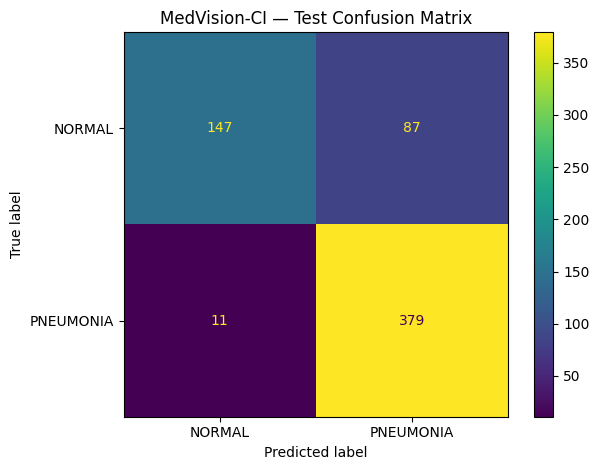

In [21]:
# visualize the confusion matrix

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(values_format="d")
plt.title("MedVision-CI — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Fine-tune the deeper ResNet18 layers

In [22]:
# Unfreeze layer4

from torch import nn
import torch
import copy
from pathlib import Path

# Freeze all parameters first
for param in model.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep the final classification layer trainable
for param in model.fc.parameters():
    param.requires_grad = True

# Use a smaller learning rate for pretrained layers
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4}
])

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

print("Layer4 trainable:",
      any(p.requires_grad for p in model.layer4.parameters()))

print("Classifier trainable:",
      any(p.requires_grad for p in model.fc.parameters()))

Trainable parameters: 8394754
Layer4 trainable: True
Classifier trainable: True


In [23]:
# training 3 more epochs

import pandas as pd

FT_EPOCHS = 3
ft_best_val_loss = float("inf")
ft_best_state = None
ft_history = []

ft_checkpoint = Path("/content/medvision_checkpoints/best_resnet18_finetuned.pth")

for epoch in range(1, FT_EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc = evaluate_model(
        model, val_loader, criterion, device
    )

    ft_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Fine-tuning {epoch}/{FT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < ft_best_val_loss:
        ft_best_val_loss = val_loss
        ft_best_state = copy.deepcopy(model.state_dict())

        torch.save(ft_best_state, ft_checkpoint)
        print("  Saved best fine-tuned checkpoint.")

display(pd.DataFrame(ft_history))
print("Best fine-tuned validation loss:", round(ft_best_val_loss, 4))

Fine-tuning 1/3 | Train Loss: 0.1152 | Train Acc: 0.9578 | Val Loss: 0.0790 | Val Acc: 0.9713
  Saved best fine-tuned checkpoint.
Fine-tuning 2/3 | Train Loss: 0.0722 | Train Acc: 0.9765 | Val Loss: 0.0698 | Val Acc: 0.9770
  Saved best fine-tuned checkpoint.
Fine-tuning 3/3 | Train Loss: 0.0520 | Train Acc: 0.9835 | Val Loss: 0.0629 | Val Acc: 0.9770
  Saved best fine-tuned checkpoint.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.115159,0.957814,0.078961,0.971264
1,2,0.072214,0.976510,0.069819,0.977011
2,3,0.051996,0.983461,0.062906,0.977011


Best fine-tuned validation loss: 0.0629


In [24]:
# restore the best fine-tuned checkpoint

model.load_state_dict(
    torch.load(ft_checkpoint, map_location=device, weights_only=True)
)
model.eval()

print("Best fine-tuned checkpoint restored.")

Best fine-tuned checkpoint restored.


## Evaluating the fine-tuned model

In [25]:
# generating predictions

import torch
import numpy as np

model.eval()

ft_y_true = []
ft_y_pred = []
ft_y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        ft_y_true.extend(labels.numpy().tolist())
        ft_y_pred.extend(predictions.cpu().numpy().tolist())
        ft_y_prob.extend(probabilities[:, 1].cpu().numpy().tolist())

ft_y_true = np.array(ft_y_true)
ft_y_pred = np.array(ft_y_pred)
ft_y_prob = np.array(ft_y_prob)

print("Test samples:", len(ft_y_true))

Test samples: 624


In [26]:
# calculating metrics & confusion matrix

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

ft_cm = confusion_matrix(
    ft_y_true, ft_y_pred, labels=[0, 1]
)

tn, fp, fn, tp = ft_cm.ravel()
ft_specificity = tn / (tn + fp) if (tn + fp) else 0.0

print("Confusion matrix:")
print(ft_cm)

print("\nFine-tuned exploratory test metrics")
print(f"Accuracy:            {accuracy_score(ft_y_true, ft_y_pred):.4f}")
print(f"Pneumonia precision: {precision_score(ft_y_true, ft_y_pred, zero_division=0):.4f}")
print(f"Pneumonia recall:    {recall_score(ft_y_true, ft_y_pred, zero_division=0):.4f}")
print(f"Specificity:         {ft_specificity:.4f}")
print(f"Pneumonia F1:        {f1_score(ft_y_true, ft_y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:             {roc_auc_score(ft_y_true, ft_y_prob):.4f}")

print("\nClassification report:")
print(classification_report(
    ft_y_true,
    ft_y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

Confusion matrix:
[[148  86]
 [  4 386]]

Fine-tuned exploratory test metrics
Accuracy:            0.8558
Pneumonia precision: 0.8178
Pneumonia recall:    0.9897
Specificity:         0.6325
Pneumonia F1:        0.8956
ROC-AUC:             0.9472

Classification report:
              precision    recall  f1-score   support

      NORMAL       0.97      0.63      0.77       234
   PNEUMONIA       0.82      0.99      0.90       390

    accuracy                           0.86       624
   macro avg       0.90      0.81      0.83       624
weighted avg       0.88      0.86      0.85       624



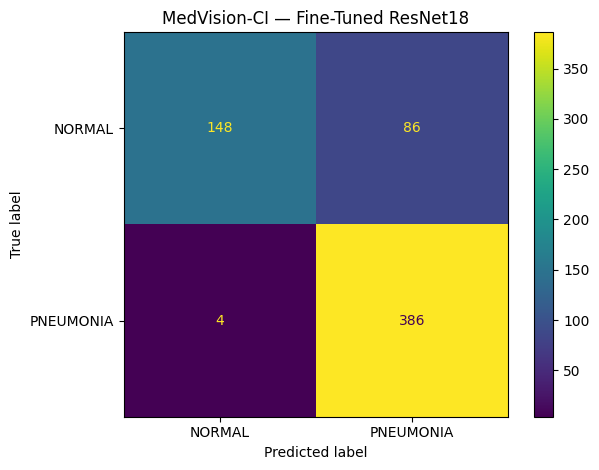

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=ft_cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(values_format="d")
plt.title("MedVision-CI — Fine-Tuned ResNet18")
plt.tight_layout()
plt.show()

### Saving model checkpoint & class labels

In [28]:
import torch
import json
from pathlib import Path

export_dir = Path("/content/medvision_export")
export_dir.mkdir(parents=True, exist_ok=True)

model_path = export_dir / "medvision_resnet18.pth"

torch.save(
    {
        "model_state_dict": model.cpu().state_dict(),
        "model_name": "resnet18",
        "num_classes": 2,
        "class_to_idx": {
            "NORMAL": 0,
            "PNEUMONIA": 1
        },
        "image_size": 224,
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225]
    },
    model_path
)

with open(export_dir / "class_labels.json", "w") as f:
    json.dump(
        {"0": "NORMAL", "1": "PNEUMONIA"},
        f,
        indent=4
    )

print("Model saved:", model_path)
print("Model size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))

Model saved: /content/medvision_export/medvision_resnet18.pth
Model size (MB): 42.71


In [29]:
from google.colab import files

files.download("/content/medvision_export/medvision_resnet18.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
files.download("/content/medvision_export/class_labels.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>